<a href="https://colab.research.google.com/github/matroxok/PRIR_LAB2/blob/main/Kopia_notatnika_PRiR2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import locale
locale.getpreferredencoding = lambda: "UTF-8"
!pip install pycuda

In [ ]:
import pycuda.driver as cuda
import pycuda.autoinit
from pycuda.compiler import SourceModule

In [ ]:
import numpy as np
import time
N = 1024
A_cpu = np.random.rand(N, N).astype(np.float32)
B_cpu = np.random.rand(N, N).astype(np.float32)
start = time.time()
C_cpu = np.matmul(A_cpu, B_cpu)
end = time.time()
czas_cpu = end - start
print(f"Mnożenie macierzy na CPU trwało: {end - start:.5f} sekund.")


Mnożenie macierzy na CPU trwało: 0.01798 sekund.


In [ ]:
import cupy as cp
import time
N = 1024
A_cpu = np.random.rand(N, N).astype(np.float32)
B_cpu = np.random.rand(N, N).astype(np.float32)
A_gpu = cp.array(A_cpu)
B_gpu = cp.array(B_cpu)
start = time.time()
C_gpu = cp.matmul(A_gpu, B_gpu)
cp.cuda.Stream.null.synchronize()  # Synchronizacja z GPU
end = time.time()
czas_gpu = end - start
print(f"Mnożenie macierzy na GPU trwało: {end - start:.5f} sekund.")


Mnożenie macierzy na GPU trwało: 0.00139 sekund.


In [ ]:
kernel_code = """
__global__ void matrixMul(float *A, float *B, float *C, int N) {
    int row = blockIdx.y * blockDim.y + threadIdx.y;
    int col = blockIdx.x * blockDim.x + threadIdx.x;
    float sum = 0.0;
    if(row < N && col < N) {
        for (int k = 0; k < N; k++) {
            sum += A[row * N + k] * B[k * N + col];
        }
        C[row * N + col] = sum;
    }
}
"""


In [ ]:
mod = SourceModule(kernel_code)
matrixMul = mod.get_function("matrixMul")


In [ ]:
C_cpu = np.empty((N, N), np.float32)

A_gpu = cuda.mem_alloc(A_cpu.nbytes)
B_gpu = cuda.mem_alloc(B_cpu.nbytes)
C_gpu = cuda.mem_alloc(C_cpu.nbytes)

cuda.memcpy_htod(A_gpu, A_cpu)
cuda.memcpy_htod(B_gpu, B_cpu)


block_size = (32, 32, 1)
grid_size = (int(N/32), int(N/32), 1)

start = time.perf_counter()

matrixMul(A_gpu, B_gpu, C_gpu, np.int32(N), block=block_size, grid=grid_size)
cuda.Context.synchronize()

czas_cuda = time.perf_counter() - start

cuda.memcpy_dtoh(C_cpu, C_gpu)

print(f"Mnożenie macierzy na GPU trwało: {czas_cuda:.5f} sekund.")



del A_gpu, B_gpu, C_gpu

Mnożenie macierzy na GPU trwało: 0.00790 sekund.


Czas mnożenia macierzy na CPU: 0.01798 sekund.
Czas mnożenia macierzy na GPU: 0.00139 sekund.
Czas mnożenia macierzy na CUDA: 0.00790 sekund.


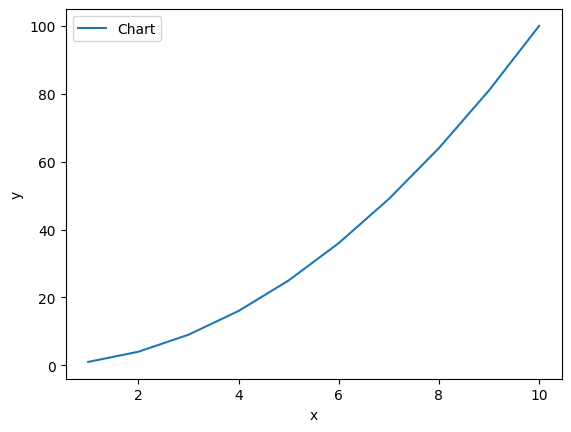

In [ ]:
print(f"Czas mnożenia macierzy na CPU: {czas_cpu:.5f} sekund.")
print(f"Czas mnożenia macierzy na GPU: {czas_gpu:.5f} sekund.")
print(f"Czas mnożenia macierzy na CUDA: {czas_cuda:.5f} sekund.")


import matplotlib.pyplot as plt
x = [ i for i in range (1 ,11) ]
# y = [ i **2 for i in range (1 ,11) ]
y=czas_cpu
y1=czas_gpu
y2=czas_cuda
plt.plot(x,y,label="Chart")
plt.legend()
plt.xlabel("x")
plt.ylabel("y")
plt.show()

In [ ]:
import matplotlib.pyplot as plt

rozmiary = [128, 256, 512, 1024]

cpu_times = []
gpu_times = []
cuda_times = []

for n in rozmiary:
    a = np.random.rand(n, n).astype(np.float32)
    b = np.random.rand(n, n).astype(np.float32)

    # CPU - NumPy
    start = time.perf_counter()
    c = np.matmul(a, b)
    cpu_times.append(time.perf_counter() - start)

    # GPU - CuPy
    a_gpu = cp.asarray(a)
    b_gpu = cp.asarray(b)

    start = time.perf_counter()
    c_gpu = cp.matmul(a_gpu, b_gpu)
    cp.cuda.Stream.null.synchronize()
    gpu_times.append(time.perf_counter() - start)

    # GPU - własny kernel CUDA
    A_gpu = cuda.mem_alloc(A_cpu.nbytes)
    B_gpu = cuda.mem_alloc(B_cpu.nbytes)
    C_gpu = cuda.mem_alloc(C_cpu.nbytes)

    cuda.memcpy_htod(A_gpu, A_cpu)
    cuda.memcpy_htod(B_gpu, B_cpu)

    start = time.perf_counter()

    matrixMul(A_gpu, B_gpu, C_gpu, np.int32(n),
              block=block_size,
              grid=((n+31)//32, (n+31)//32, 1))

    cuda.Context.synchronize()
    cuda_times.append(time.perf_counter() - start)

    del A_gpu, B_gpu, C_gpu

    print("Przetestowano:", n, "x", n)


Przetestowano: 128 x 128
Przetestowano: 256 x 256
Przetestowano: 512 x 512
Przetestowano: 1024 x 1024


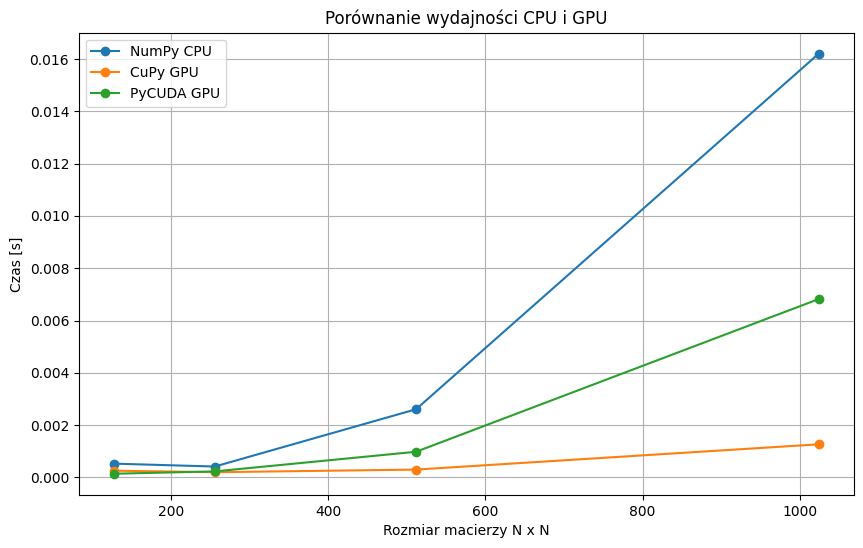

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(rozmiary, cpu_times, "o-", label="NumPy CPU")
plt.plot(rozmiary, gpu_times, "o-", label="CuPy GPU")
plt.plot(rozmiary, cuda_times, "o-", label="PyCUDA GPU")

plt.xlabel("Rozmiar macierzy N x N")
plt.ylabel("Czas [s]")
plt.title("Porównanie wydajności CPU i GPU")
plt.legend()
plt.grid()
plt.show()
